In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df_house = pd.read_csv("data/eda.csv")
df_house.head()

,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,...,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,date,price
0,7129300520,3.0,1.00,1180.0,5650.0,1.0,NaN,0.0,3,7,...,0.0,1955,0.0,98178,47.5112,-122.257,1340.0,5650.0,2014-10-13,221900.0
1,6414100192,3.0,2.25,2570.0,7242.0,2.0,0.0,0.0,3,7,...,400.0,1951,19910.0,98125,47.7210,-122.319,1690.0,7639.0,2014-12-09,538000.0
2,5631500400,2.0,1.00,770.0,10000.0,1.0,0.0,0.0,3,6,...,0.0,1933,NaN,98028,47.7379,-122.233,2720.0,8062.0,2015-02-25,180000.0
3,2487200875,4.0,3.00,1960.0,5000.0,1.0,0.0,0.0,5,7,...,910.0,1965,0.0,98136,47.5208,-122.393,1360.0,5000.0,2014-12-09,604000.0
4,1954400510,3.0,2.00,1680.0,8080.0,1.0,0.0,0.0,3,8,...,0.0,1987,0.0,98074,47.6168,-122.045,1800.0,7503.0,2015-02-18,510000.0


In [3]:
# Untouched backup of the raw data
df_raw = df_house.copy()

### Step A: Column profile

Before cleaning, we summarize every column: its data type, how many values are missing,
how many distinct values it has, its range and a few examples.
This shows us what each column really contains and where to look more closely.

In [16]:
import pandas as pd

df_house["date"] = pd.to_datetime(df_house["date"])

rows = []
for col in df_house.columns:
    s = df_house[col]
    rows.append({
        "column":    col,
        "type":      str(s.dtype),
        "count":     s.count(),
        "missing":   s.isna().sum(),
        "missing_%": round(s.isna().mean() * 100, 2),
        "unique":    s.nunique(),
        "min":       s.min(),
        "5%":        s.quantile(0.05),
        "median":    s.median(),
        "95%":       s.quantile(0.95),
        "max":       s.max(),
    })

overview = pd.DataFrame(rows).set_index("column")

pd.set_option("display.max_columns", None)
overview

,type,count,missing,missing_%,unique,min,5%,median,95%,max
column,,,,,,,,,,
id,int64,21596,0,0.00,21419,1000102,512675376.25,3904930470.0,9297300416.25,9900000190
bedrooms,float64,21596,0,0.00,11,1.0,2.0,3.0,5.0,11.0
bathrooms,float64,21596,0,0.00,29,0.5,1.0,2.25,3.5,8.0
sqft_living,float64,21596,0,0.00,1034,370.0,940.0,1910.0,3760.0,13540.0
sqft_lot,float64,21596,0,0.00,9776,520.0,1800.75,7619.0,43308.75,1651359.0
floors,float64,21596,0,0.00,6,1.0,1.0,1.5,2.0,3.5
waterfront,float64,19205,2391,11.07,2,0.0,0.0,0.0,0.0,1.0
view,float64,21533,63,0.29,5,0.0,0.0,0.0,2.0,4.0
condition,int64,21596,0,0.00,5,1,3.0,3.0,5.0,5


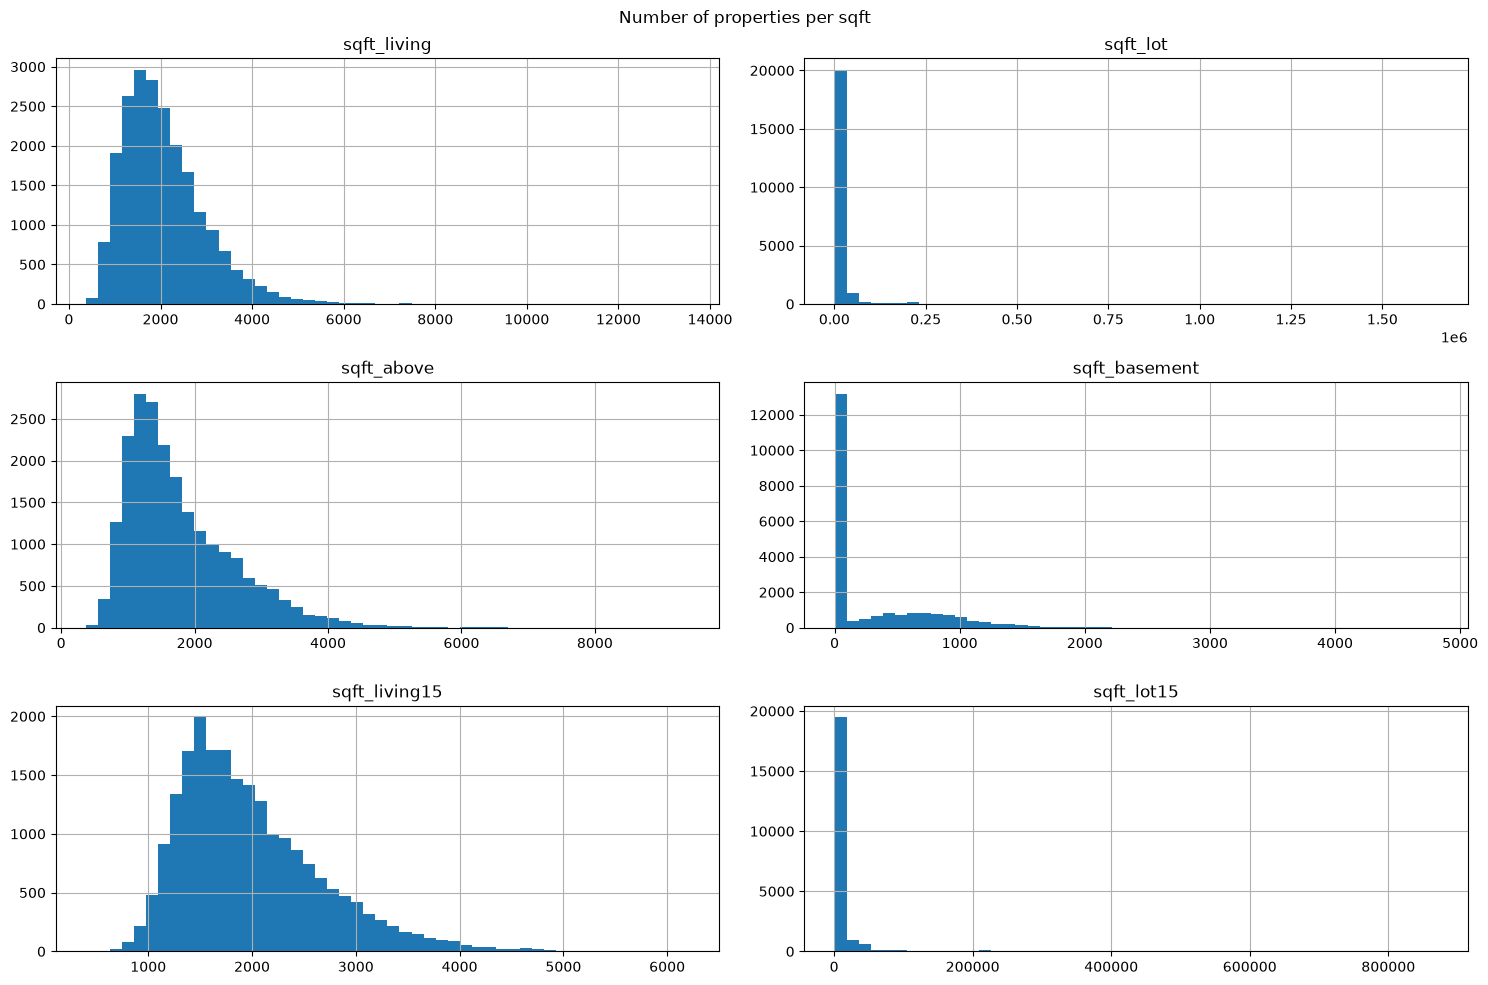

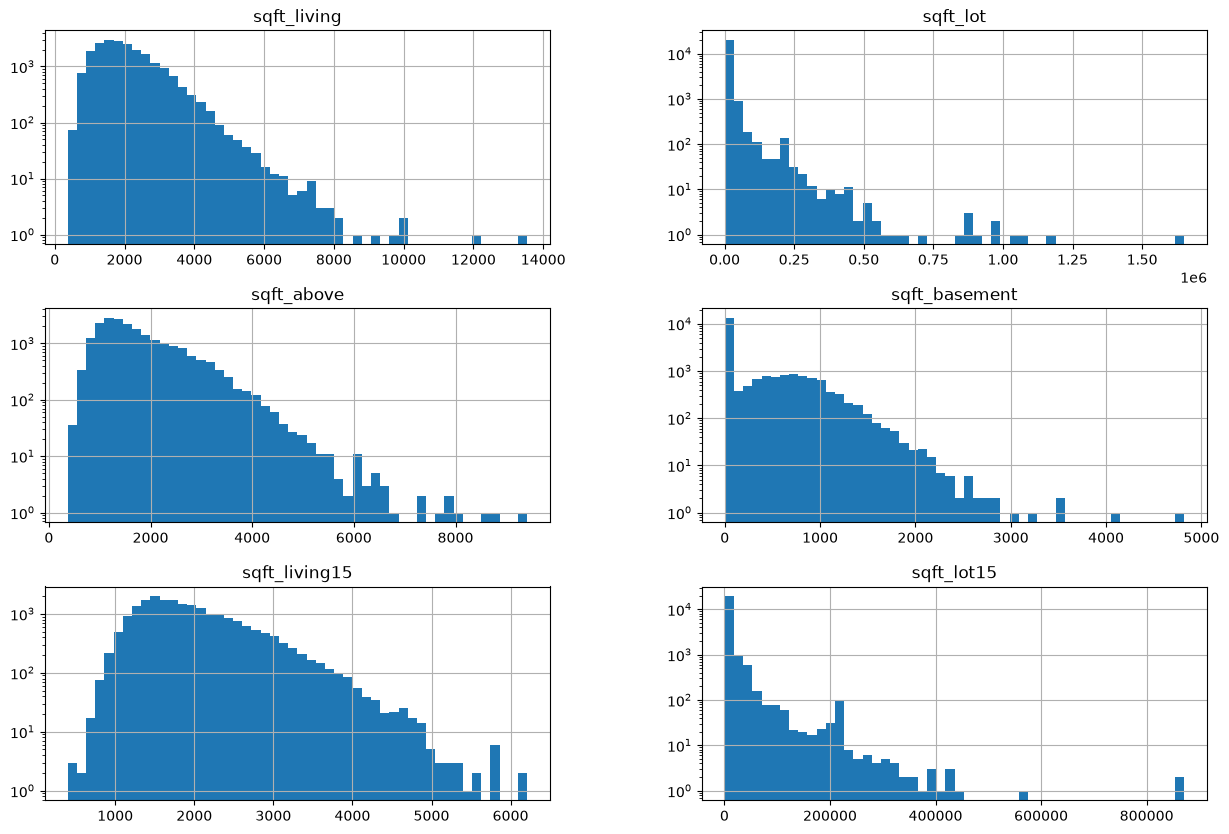

In [ ]:
import matplotlib.pyplot as plt

sqft_cols = [c for c in df_house.columns if c.startswith("sqft")]

df_house[sqft_cols].hist(bins=50, figsize=(15, 10))
plt.suptitle("Number of properties per sqft")
plt.tight_layout()

df_house[sqft_cols].hist(bins=50, figsize=(15, 10), log=True)
plt.show()

In [ ]:
#remove outliers for left graghs
before = len(df_house)

df_house = df_house[
    (df_house["sqft_living"] <= 8000) &
    (df_house["sqft_above"] <= 7000) &
    (df_house["sqft_living15"] <= 5000)&
    (df_house["sqft_lot"] <= 700000)&
   (df_house["sqft_lot15"] <= 500000)
]

print(f"Removed {before - len(df_house)} rows, {len(df_house)} left")

#Removed 27 rows, 21569 left
#Removed 3 rows, 21560 left
#Removed 10 rows, 21550 left

Removed 6 rows, 21550 left


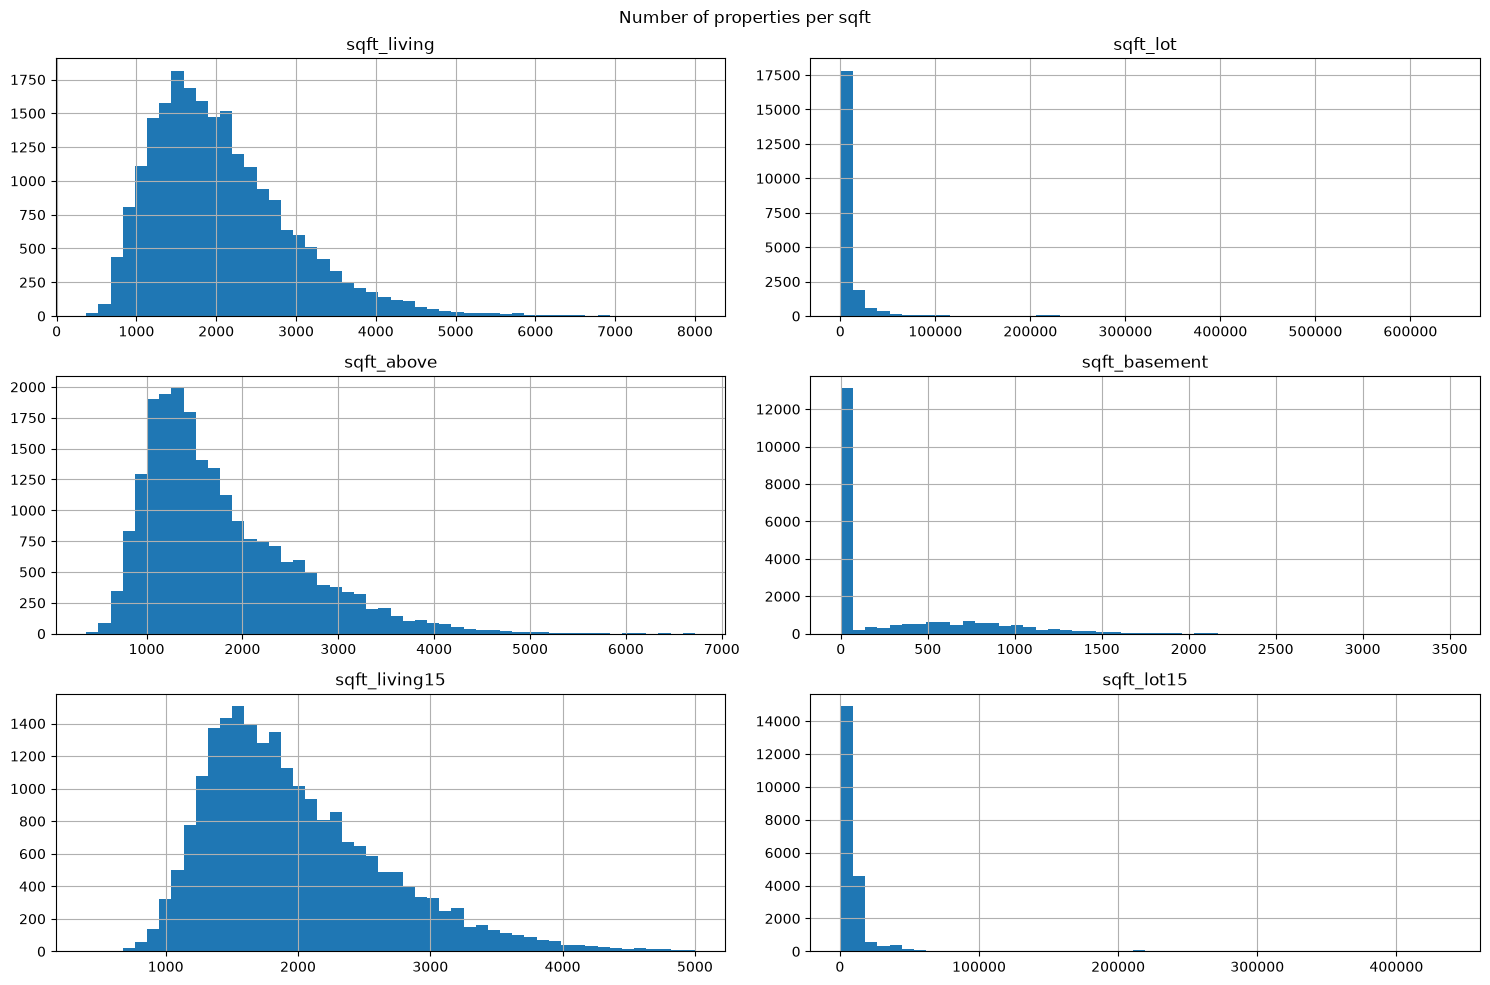

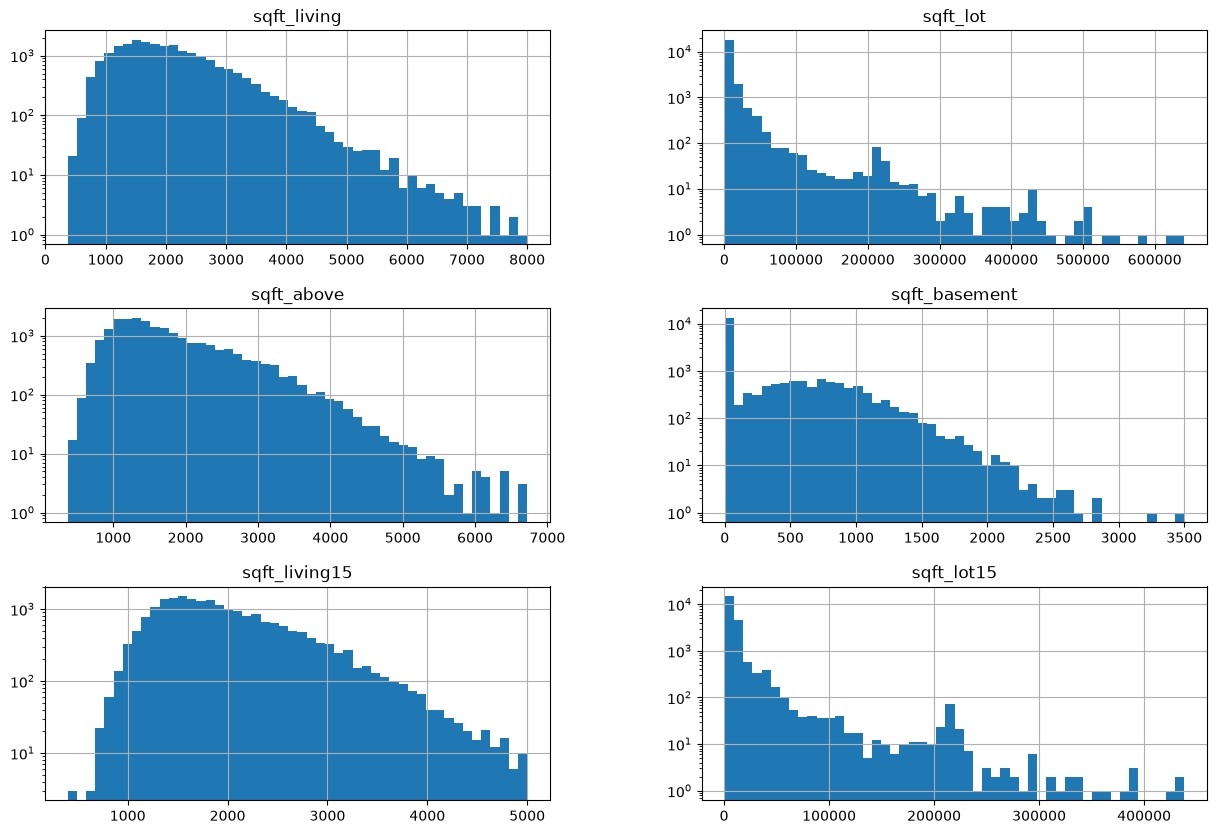

In [31]:
import matplotlib.pyplot as plt

sqft_cols = [c for c in df_house.columns if c.startswith("sqft")]

df_house[sqft_cols].hist(bins=50, figsize=(15, 10))
plt.suptitle("Number of properties per sqft")
plt.tight_layout()

df_house[sqft_cols].hist(bins=50, figsize=(15, 10), log=True)
plt.show()

### Date format (`date`)

**Problem:** `date` is stored as text (`str`).

**Action:** Convert it to a proper datetime type and check that the result is valid:
- no values failed to convert,
- all sales fall in the expected period (May 2014 to May 2015).

In [6]:
# Before: look at the current type and a few raw values
print("dtype before:", df_house["date"].dtype)
print(df_house["date"].head(3).tolist())

# Convert text to datetime (the file uses the format YYYY-MM-DD)
df_house["date"] = pd.to_datetime(df_house["date"], format="%Y-%m-%d")

# After: check the result
print("\ndtype after:", df_house["date"].dtype)
print("Missing dates:", df_house["date"].isna().sum())
print("Earliest sale:", df_house["date"].min().date())
print("Latest sale:  ", df_house["date"].max().date())

dtype before: str
['2014-10-13', '2014-12-09', '2015-02-25']

dtype after: datetime64[us]
Missing dates: 0
Earliest sale: 2014-05-02
Latest sale:   2015-05-27


In [44]:
col = df_house["yr_renovated"]

print("Missing:", col.isna().sum())
print("Zeros (never renovated):", (col == 0).sum())
print("Valid years (1900-2015):", col.between(1900, 2015).sum())
print("Values above 2015 (extra zero):", (col > 2015).sum())

print("\nAll values above 2015:")
print(col[col > 2015].value_counts().sort_index())

Missing: 3837
Zeros (never renovated): 16973
Valid years (1900-2015): 14
Values above 2015 (extra zero): 726

All values above 2015:
yr_renovated
19340.0     1
19400.0     2
19440.0     1
19450.0     3
19460.0     1
           ..
20100.0    15
20110.0     9
20120.0     8
20130.0    31
20140.0    73
Name: count, Length: 68, dtype: int64


In [47]:
# 1. Flag missing rows, then fill them with 0 (= not renovated)
df_house["renovated_was_missing"] = df_house["yr_renovated"].isna().astype(int)
df_house["yr_renovated"] = df_house["yr_renovated"].fillna(0)

# 2. Fix the extra zero: 19910 -> 1991, 20140 -> 2014, etc.
typo_mask = df_house["yr_renovated"] > 2020
print("Values corrected:", typo_mask.sum())
df_house.loc[typo_mask, "yr_renovated"] = df_house.loc[typo_mask, "yr_renovated"] / 10



Values corrected: 0


removing the house with 33 bedrooms:

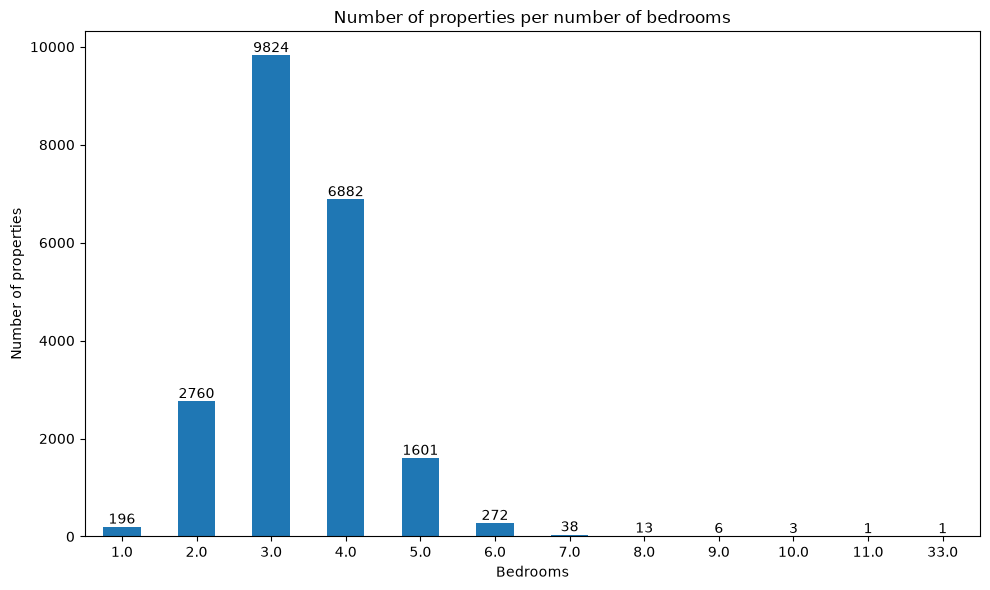

In [7]:
bedroom_counts = df_house["bedrooms"].value_counts().sort_index()

ax = bedroom_counts.plot(kind="bar", figsize=(10, 6))
ax.bar_label(ax.containers[0])          # show the count on each bar
plt.title("Number of properties per number of bedrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Number of properties")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [8]:
cols_to_show = ["id", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors", "price", "zipcode"]

print("Houses with 0 bedrooms or 8+ bedrooms:")
display(
    df_house[(df_house["bedrooms"] == 0) | (df_house["bedrooms"] >= 8)]
    .sort_values("bedrooms")[cols_to_show]
)

Houses with 0 bedrooms or 8+ bedrooms:


,id,bedrooms,bathrooms,sqft_living,sqft_lot,floors,price,zipcode
1658,9126101740,8.0,5.00,2800.0,2580.0,2.0,490000.0,98122
18462,1346300150,8.0,4.00,7710.0,11750.0,3.5,3300000.0,98112
17221,1338600225,8.0,3.50,4440.0,6480.0,2.0,1970000.0,98112
15656,8141200080,8.0,2.75,2530.0,4800.0,2.0,680000.0,98112
15056,7418000130,8.0,3.25,4300.0,10441.0,2.0,430000.0,98059
12872,8813400155,8.0,3.75,3460.0,4600.0,2.0,808000.0,98105
9443,2769600590,8.0,4.00,4020.0,7500.0,1.0,900000.0,98107
9068,6746700615,8.0,2.50,2280.0,3000.0,1.5,700000.0,98105
10946,1652500060,8.0,2.75,4040.0,20666.0,1.0,1650000.0,98004
6168,1873400020,8.0,2.75,2790.0,6695.0,1.0,340000.0,98133


In [10]:
df_house = df_house[df_house["bedrooms"] != 33].copy()

print(len(df_house), "rows in df_house")


21596 rows in df_house


### Column: `sqft_basement`

**Meaning:** square footage of the basement (0 = no basement).
**Problem:** 452 values are missing (2.09%).

**Check before filling:** `sqft_living = sqft_above + sqft_basement`.
For the rows with a missing basement, we calculate `sqft_living - sqft_above`.
If this is 0, the house has no basement and filling with 0 is correct. If it is above 0, the house does have a basement.

In [13]:
# 1. Flag the rows that were missing (run this BEFORE filling)
df_house["basement_was_missing"] = df_house["sqft_basement"].isna().astype(int)
print("Missing basement values:", df_house["basement_was_missing"].sum())

# 2. Calculated basement size
implied_basement = df_house["sqft_living"] - df_house["sqft_above"]

# 3. Does the formula hold where the basement is known?
known = df_house["sqft_basement"].notna()
match_rate = (implied_basement[known] == df_house.loc[known, "sqft_basement"]).mean()
print("Formula matches known values in {:.1%} of rows".format(match_rate))


Missing basement values: 0
Formula matches known values in 100.0% of rows


In [15]:
df_house["sqft_basement"] = df_house["sqft_basement"].fillna(implied_basement)

print("Missing after fill:", df_house["sqft_basement"].isna().sum())
print("Negative values:", (df_house["sqft_basement"] < 0).sum())

df_house["basement_was_missing"] = df_house["sqft_basement"].isna().astype(int)
print("Missing basement values:", df_house["basement_was_missing"].sum())

Missing after fill: 0
Negative values: 0
Missing basement values: 0


*** waterfront 
 The remaining missing values were filled with 0 (no waterfront), because waterfront houses are rare (___ %) and almost all missing rows are far from the shoreline or have a low view. A flag column `waterfront_was_missing` marks the filled rows. No rows were removed.

In [32]:
# For each id, take the known waterfront value (if any row has one)
known_by_id = df_house.dropna(subset=["waterfront"]).groupby("id")["waterfront"].first()

missing_rows = df_house["waterfront"].isna()
fillable = df_house.loc[missing_rows, "id"].isin(known_by_id.index)
print("Missing rows that can be filled from another sale of the same house:", fillable.sum())

# What would those values be?
print(df_house.loc[missing_rows & df_house["id"].isin(known_by_id.index), "id"].map(known_by_id).value_counts())

Missing rows that can be filled from another sale of the same house: 0
Series([], Name: count, dtype: int64)


In [33]:
df_house["waterfront"] = df_house["waterfront"].fillna(0)
print("Missing after fill:", df_house["waterfront"].isna().sum())
print(df_house["waterfront"].value_counts())

Missing after fill: 0
waterfront
0.0    21407
1.0      143
Name: count, dtype: int64


In [ ]:
#flot to int waterfront
df_house["waterfront"] = df_house["waterfront"].astype(int)


**view
set nan to 0

In [ ]:
print("Missing values:", df_house["view"].isna().sum())
print("\nValue counts (including missing):")
print(df_house["view"].value_counts(dropna=False))

Missing values: 63

Value counts (including missing):
view
0.0    19400
2.0      950
3.0      497
1.0      330
4.0      310
NaN       63
Name: count, dtype: int64


In [40]:
# 1. Rename
df_house = df_house.rename(columns={"view": "view_quality"})

# 2. Flag the rows that were missing (run this BEFORE filling)
df_house["view_was_missing"] = df_house["view_quality"].isna().astype(int)

# 3. Fill missing values with 0
df_house["view_quality"] = df_house["view_quality"].fillna(0)

# Check
print("Missing after fill:", df_house["view_quality"].isna().sum())
print(df_house["view_quality"].value_counts().sort_index())

Missing after fill: 0
view_quality
0.0    19463
1.0      330
2.0      950
3.0      497
4.0      310
Name: count, dtype: int64


In [48]:
import pandas as pd

df_house["date"] = pd.to_datetime(df_house["date"])

rows = []
for col in df_house.columns:
    s = df_house[col]
    rows.append({
        "column":    col,
        "type":      str(s.dtype),
        "count":     s.count(),
        "missing":   s.isna().sum(),
        "missing_%": round(s.isna().mean() * 100, 2),
        "unique":    s.nunique(),
        "min":       s.min(),
        "5%":        s.quantile(0.05),
        "median":    s.median(),
        "95%":       s.quantile(0.95),
        "max":       s.max(),
    })

overview = pd.DataFrame(rows).set_index("column")

pd.set_option("display.max_columns", None)
overview

,type,count,missing,missing_%,unique,min,5%,median,95%,max
column,,,,,,,,,,
id,int64,21550,0,0.0,21373,1000102,510766853.0,3904960695.0,9297300491.0,9900000190
bedrooms,float64,21550,0,0.0,11,1.0,2.0,3.0,5.0,11.0
bathrooms,float64,21550,0,0.0,26,0.5,1.0,2.25,3.5,7.5
sqft_living,float64,21550,0,0.0,1013,370.0,940.0,1910.0,3740.0,8000.0
sqft_lot,float64,21550,0,0.0,9740,520.0,1800.0,7605.5,42788.75,641203.0
floors,float64,21550,0,0.0,6,1.0,1.0,1.5,2.0,3.5
waterfront,int64,21550,0,0.0,2,0,0.0,0.0,0.0,1
view_quality,float64,21550,0,0.0,5,0.0,0.0,0.0,2.0,4.0
condition,int64,21550,0,0.0,5,1,3.0,3.0,5.0,5


In [50]:
import os

# Copy of the cleaned data (helper column removed)
cleandataset = df_house.copy()

# Save it as a CSV file
cleandataset.to_csv("cleandataset.csv", index=False)

# Show where the file was saved
print(os.path.abspath("cleandataset.csv"))
print(len(cleandataset), "rows saved")

/Users/xpourta/Documents/neufische/eda_project/cleandataset.csv
21550 rows saved
